<a href="https://colab.research.google.com/github/rivindu02/EN3160-Image-Processing-and-Computer-Vision/blob/main/assignment02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 02

**Question 01**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def create_laplacian_of_gaussian_kernel(sigma):
    """
    Creates a scale-normalized Laplacian of Gaussian (LoG) filter kernel.
    """
    half_width = int(3 * sigma)
    size = 2 * half_width + 1
    x, y = np.arange(-half_width, half_width + 1), np.arange(-half_width, half_width + 1)
    X, Y = np.meshgrid(x, y)
    r_squared = X**2 + Y**2
    log_kernel = ((r_squared / (2 * sigma**2) - 1) * np.exp(-r_squared / (2 * sigma**2))) / (np.pi * sigma**4)
    scaled_log_kernel = (sigma ** 2) * log_kernel
    return scaled_log_kernel

In [ ]:
# Load the image
image = cv2.imread('the_berry_farms_sunflower_field.jpeg', cv2.IMREAD_REDUCED_COLOR_4)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# --- 1. Invert the image ---
image_inverted = 255 - image_gray

# --- 2. Create an aggressive feathered mask ---
height = image_gray.shape[0]
mask_hard = np.zeros(image_gray.shape, dtype="uint8")
# KEY CHANGE: This cutoff defines the ABSOLUTE UPPER LIMIT for any detected sunflower.
sky_cutoff = int(height * 0.49) # Slightly lower to catch all treeline
mask_hard[sky_cutoff:, :] = 255
mask_feathered = cv2.GaussianBlur(mask_hard, (81, 81), 0)

# --- 3. Apply the mask and normalize ---
image_clean_input = (image_inverted / 255.0 * mask_feathered / 255.0)
image_clean_input = (image_clean_input * 255).astype(np.uint8)

print("Image successfully pre-processed with aggressive mask.")

Image successfully pre-processed with aggressive mask.


In [ ]:
# Define the range of radii and corresponding sigmas
radii = np.arange(5, 25, 1)
sigma_values = radii / np.sqrt(2)
num_scales = len(sigma_values)

h, w = image_clean_input.shape
scale_space = np.zeros((h, w, num_scales), dtype=np.float32)
image_float = image_clean_input.astype(np.float32)

print("Building scale-space...")
for i, sigma in enumerate(sigma_values):
    log_kernel = create_laplacian_of_gaussian_kernel(sigma)
    response = cv2.filter2D(image_float, -1, log_kernel)
    scale_space[:, :, i] = response**2

print("Scale-space built successfully.")

Building scale-space...
Scale-space built successfully.


In [ ]:
all_blobs_raw = []
print("Detecting local maxima...")

# Loop through each scale to find maxima
for i in range(num_scales):
    current_response = scale_space[:, :, i]
    threshold = np.percentile(current_response, 99.6)

    for y in range(1, h - 1):
        for x in range(1, w - 1):
            pixel_val = current_response[y, x]
            if pixel_val > threshold and np.max(current_response[y-1:y+2, x-1:x+2]) == pixel_val:
                is_max_in_scale = True
                if i > 0 and pixel_val < scale_space[y, x, i-1]: is_max_in_scale = False
                if i < num_scales - 1 and pixel_val < scale_space[y, x, i+1]: is_max_in_scale = False
                if is_max_in_scale:
                    all_blobs_raw.append((x, y, radii[i]))

print(f"Found {len(all_blobs_raw)} raw blobs.")

# --- Apply Non-Maximum Suppression ---
blobs_after_nms = []
all_blobs_raw.sort(key=lambda b: b[2], reverse=True) # Sort by radius, largest first

for (x1, y1, r1) in all_blobs_raw:
    is_overlapping = False
    for (x2, y2, r2) in blobs_after_nms:
        dist = np.sqrt((x1-x2)**2 + (y1-y2)**2)
        if dist < (r1 + r2) * 0.5:
            is_overlapping = True
            break
    if not is_overlapping:
        blobs_after_nms.append((x1, y1, r1))

print(f"Kept {len(blobs_after_nms)} blobs after non-maximum suppression.")


# --- THE DEFINITIVE FIX: STRICT POST-DETECTION Y-COORDINATE FILTER ---
final_blobs = []
for (x, y, r) in blobs_after_nms:
    # Only keep blobs whose center is STRICTLY BELOW the defined sky_cutoff
    if y > sky_cutoff:
        final_blobs.append((x, y, r))

print(f"Final count: {len(final_blobs)} sunflowers after strict positional filtering.")

Detecting local maxima...
Found 29 raw blobs.
Kept 28 blobs after non-maximum suppression.
Final count: 24 sunflowers after strict positional filtering.



Parameters of the 5 largest circles detected:

Rank       Center (x, y)        Radius (pixels)     
--------------------------------------------------
#1         (282    , 338    ) 10                  
#2         (106    , 255    ) 8                   
#3         (178    , 261    ) 8                   
#4         (179    , 327    ) 8                   
#5         (274    , 258    ) 7                   


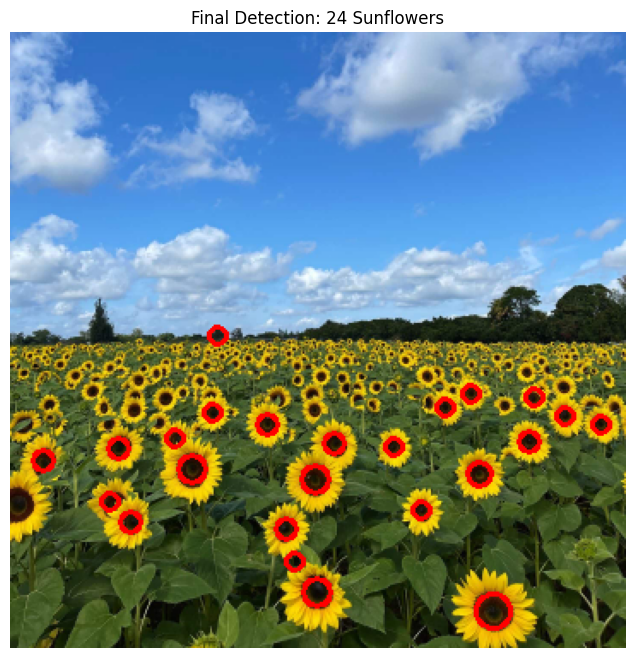

In [ ]:
# Report the parameters of the largest circles
final_blobs.sort(key=lambda b: b[2], reverse=True)
print("\nParameters of the 5 largest circles detected:\n")
print("{:<10} {:<20} {:<20}".format("Rank", "Center (x, y)", "Radius (pixels)"))
print("-" * 50)
for i, (x, y, r) in enumerate(final_blobs[:5]):
    print("{:<10} ({:<7}, {:<7}) {:<20}".format(f"#{i+1}", x, y, r))

# Visualize the final detections
image_with_circles = image.copy()
for (x, y, r) in final_blobs:
    cv2.circle(image_with_circles, (x, y), r, (0, 0, 255), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(image_with_circles, cv2.COLOR_BGR2RGB))
plt.title(f'Final Detection: {len(final_blobs)} Sunflowers')
plt.axis('off')
plt.show()